# Universidad Autónoma del Estado de México — Centro Universitario UAEM Zumpango

**Asignatura:** Investigación de Operaciones  
**Actividad:** Práctica 4 — Programación lineal (producción IoT)  
**Programa educativo:** Ingeniería en Computación  
**Integrantes:** ________________________________  
**Docente:** ________________________________  
**Periodo:** 2026B

## 1. Descripción y planteamiento del problema

Imaginemos una pequeña empresa que fabrica equipos para instalar sistemas de monitoreo inteligente en edificios. La empresa ofrece dos productos: **nodos sensores (X)**, que permiten recopilar información del entorno, y **gateways (Y)**, que reciben y transmiten esos datos hacia otros sistemas.

La empresa quiere obtener la mayor utilidad posible cada semana, pero no puede fabricar una cantidad ilimitada. Para producir los dispositivos necesita tiempo de **ensamblaje**, acceso a un **banco de pruebas** y **componentes electrónicos**. Cada producto consume estos recursos de manera diferente, y las cantidades disponibles son limitadas.

La pregunta central es: **¿cuántos nodos sensores y cuántos gateways conviene producir por semana para obtener la mayor utilidad sin superar los recursos disponibles?**

Para responder utilizaremos **programación lineal**, una técnica que permite convertir una situación de producción en variables, una función que queremos maximizar y varias restricciones. En este ejercicio trabajamos con la **utilidad de contribución**, es decir, el monto que aporta cada producto después de considerar sus costos variables, y no con el ingreso total de ventas.

## 2. Cómo se construye el modelo matemático

Primero definimos nuestras **variables de decisión**:

- **$x$:** cantidad de nodos sensores (X) que se fabricarán en una semana.
- **$y$:** cantidad de gateways (Y) que se fabricarán en una semana.

Cada nodo aporta **$500 MXN** de utilidad y cada gateway aporta **$750 MXN**. Por lo tanto, la utilidad semanal total es la suma de lo que obtenemos por ambos productos.

**Función objetivo:** queremos encontrar la combinación que haga lo más grande posible el valor de $Z$:

$$\max Z=500x+750y$$

Sin embargo, debemos respetar tres límites de producción:

1. **Ensamblaje:** cada dispositivo necesita una unidad de capacidad y solo hay **48 unidades** disponibles. Por eso, $x+y\leq48$.
2. **Banco de pruebas:** cada nodo consume **2 unidades de tiempo** y cada gateway **4**. La capacidad total es de **136 unidades**: $2x+4y\leq136$.
3. **Componentes electrónicos:** cada nodo requiere **3 unidades de componentes** y cada gateway **2**. Se dispone de **120 unidades**: $3x+2y\leq120$.

También agregamos las condiciones **$x\geq0$** y **$y\geq0$**, porque no tendría sentido producir cantidades negativas.

En esta primera formulación, el programa considera las cantidades como números continuos. Al final revisaremos que la solución encontrada sea un número entero de dispositivos, ya que no podemos fabricar una fracción de un equipo.

## 3. Bibliotecas utilizadas

Importamos **NumPy** para trabajar con operaciones numéricas, **Pandas** para organizar datos en tablas y **Matplotlib** para representar las restricciones en gráficas. Además, utilizamos **SciPy** para calcular la mejor solución mediante una herramienta de optimización. Estas bibliotecas nos ayudarán tanto a resolver el problema como a explicar visualmente el resultado.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import linprog
from itertools import combinations
from IPython.display import display
plt.rcParams['figure.figsize']=(10,6)

## 4. Organización de los datos de producción

Antes de realizar los cálculos, colocamos la información en una tabla. Cada fila corresponde a un recurso: ensamblaje, pruebas o componentes. Las columnas **Nodo X** y **Gateway Y** indican cuánto consume cada producto, mientras que **Disponible** muestra la capacidad máxima que la empresa puede utilizar durante la semana.

Por ejemplo, fabricar **un nodo y un gateway** requiere **2 + 4 = 6 unidades de banco de pruebas**, ya que cada producto utiliza ese recurso de una manera diferente. Esto ilustra por qué es importante registrar el consumo de cada producto por separado.

Con estos datos también construimos las matrices que utilizará Python para comprobar las restricciones y encontrar la mejor combinación de producción. Las capacidades se expresan en **unidades propias de cada recurso**; no debemos interpretarlas como si todas fueran horas, piezas o minutos.

In [ ]:
recursos=pd.DataFrame({'Recurso':['Ensamblaje','Banco de pruebas','Componentes'],
                           'Nodo X':[1,2,3],'Gateway Y':[1,4,2],
                           'Disponible':[48,136,120]})
display(recursos)
A=np.array([[1.,1.],[2.,4.],[3.,2.]])
b=np.array([48.,136.,120.])
utilidad=np.array([500.,750.])
print('Maximizar Z = 500x + 750y')

,Recurso,Nodo X,Gateway Y,Disponible
0,Ensamblaje,1,1,48
1,Banco de pruebas,2,4,136
2,Componentes,3,2,120


Maximizar Z = 500x + 750y


## 5. Representación de las restricciones en el plano

Ahora dibujamos las tres restricciones para observar qué combinaciones de producción son posibles. En las gráficas, el eje horizontal representa la cantidad de **nodos sensores ($x$)** y el eje vertical la cantidad de **gateways ($y$)**.

Cada línea señala el límite de uno de los recursos. Las combinaciones que quedan del lado permitido de todas las líneas forman la **región factible**, es decir, el conjunto de decisiones que la empresa realmente puede llevar a cabo sin exceder su capacidad.

El programa crea **tres gráficas progresivas**. Primero muestra únicamente el límite de ensamblaje; después incorpora el banco de pruebas; y finalmente también considera los componentes. La zona sombreada se va ajustando a medida que agregamos condiciones.

Esta representación permite entender algo importante: **aunque una combinación produzca mucha utilidad, no sirve si necesita más recursos de los que están disponibles**. Solo buscamos la mejor alternativa dentro de la región factible.

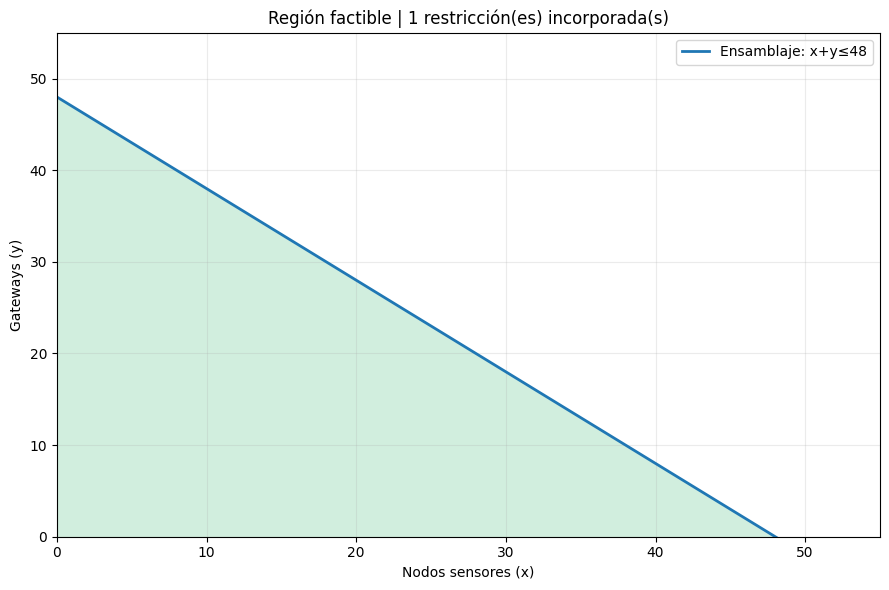

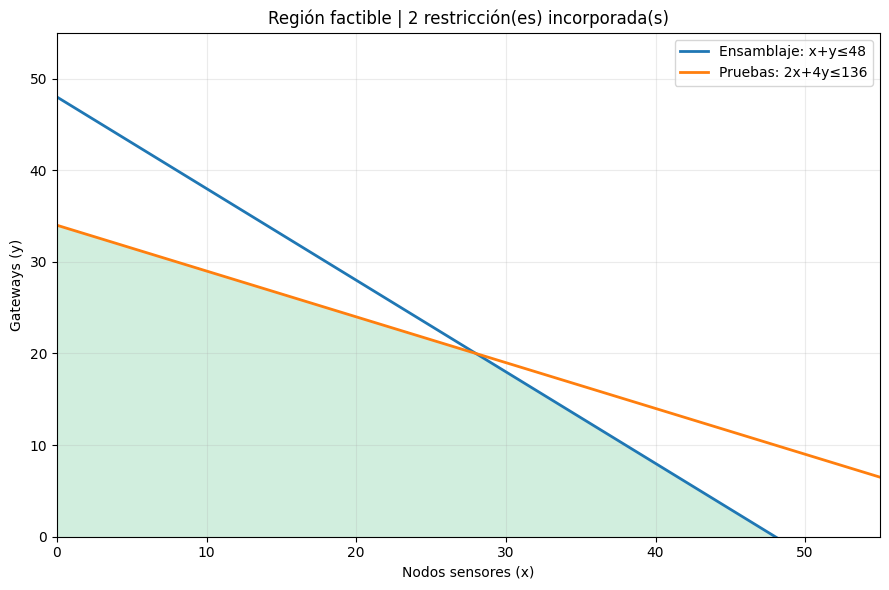

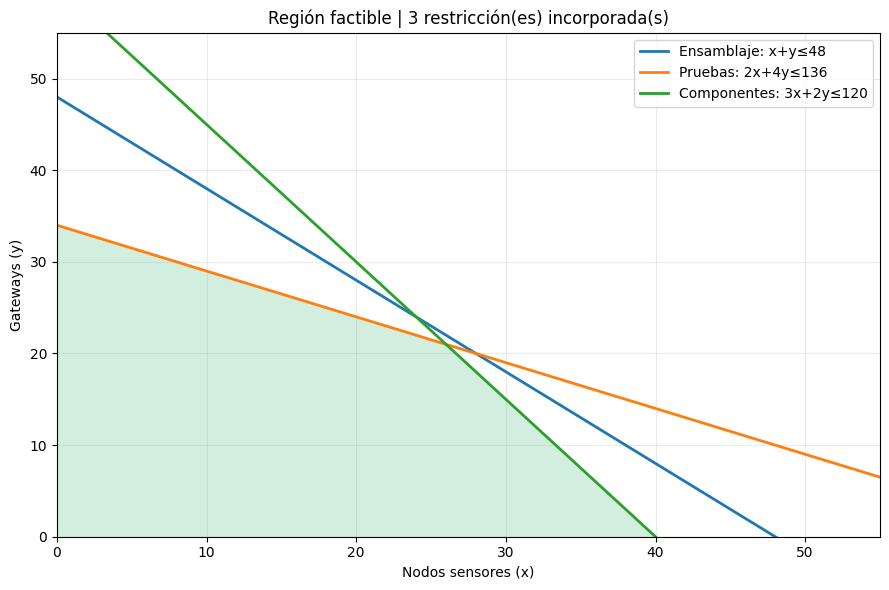

In [ ]:
xx=np.linspace(0,55,450)
yy=np.linspace(0,55,450)
X,Y=np.meshgrid(xx,yy)
nombres=['Ensamblaje: x+y≤48','Pruebas: 2x+4y≤136','Componentes: 3x+2y≤120']
figuras=[]
for k in range(1,4):
 fig,ax=plt.subplots(figsize=(9,6))
 factible=(X>=0)&(Y>=0)
 for j in range(k):factible &= (A[j,0]*X+A[j,1]*Y<=b[j]+1e-9)
 ax.contourf(X,Y,factible.astype(int),levels=[.5,1.5],colors=['#c2e9d4'],alpha=.75)
 for j in range(k):
  ax.plot(xx,(b[j]-A[j,0]*xx)/A[j,1],lw=2,label=nombres[j])
 ax.set(xlim=(0,55),ylim=(0,55),xlabel='Nodos sensores (x)',ylabel='Gateways (y)',title=f'Región factible | {k} restricción(es) incorporada(s)')
 ax.grid(alpha=.25);ax.legend(loc='upper right');plt.tight_layout();plt.show()

## 6. Búsqueda de los puntos extremos o vértices

Una vez identificada la región factible, buscamos sus **vértices**, que son los puntos donde se cruzan las líneas de restricción o los ejes y que cumplen todas las condiciones del problema.

¿Por qué revisamos estos puntos? Porque en un problema de programación lineal de dos variables, cuando existe una solución óptima y la región está acotada, **al menos una solución óptima se encuentra en un vértice**. Por ello, en lugar de probar combinaciones al azar, podemos comparar de forma ordenada los valores que toma la utilidad en esos puntos.

El código calcula las intersecciones, descarta las que exceden algún recurso y obtiene para cada punto el valor de **$Z=500x+750y$**. Finalmente, ordena los resultados de mayor a menor utilidad. Así podemos reconocer cuál combinación ofrece el mejor beneficio dentro de los límites establecidos.

In [ ]:
rectas=[(np.array([1.,0.]),0.,'x=0'),(np.array([0.,1.]),0.,'y=0')]
rectas += [(A[i],b[i],nombres[i]) for i in range(3)]
candidatos=[]
for (a1,b1,n1),(a2,b2,n2) in combinations(rectas,2):
 mat=np.vstack([a1,a2])
 if abs(np.linalg.det(mat))<1e-10:continue
 punto=np.linalg.solve(mat,np.array([b1,b2]))
 if np.all(punto>=-1e-8) and np.all(A@punto<=b+1e-8):
  if not any(np.allclose(punto,z['punto']) for z in candidatos):
   candidatos.append({'punto':punto,'origen':n1+' / '+n2})
filas=[{'x':round(z['punto'][0],5),'y':round(z['punto'][1],5),
        'Z (MXN)':round(float(utilidad@z['punto']),2),'Intersección':z['origen']} for z in candidatos]
tabla=pd.DataFrame(filas).sort_values('Z (MXN)',ascending=False).reset_index(drop=True)
display(tabla)
print('Mejor vértice:',tuple(tabla.loc[0,['x','y']]),'| utilidad:',tabla.loc[0,'Z (MXN)'])

,x,y,Z (MXN),Intersección
0,26.0,21.0,28750.0,Pruebas: 2x+4y≤136 / Componentes: 3x+2y≤120
1,0.0,34.0,25500.0,x=0 / Pruebas: 2x+4y≤136
2,40.0,0.0,20000.0,y=0 / Componentes: 3x+2y≤120
3,0.0,0.0,0.0,x=0 / y=0


Mejor vértice: (np.float64(26.0), np.float64(21.0)) | utilidad: 28750.0


## 7. Comprobación de la solución con SciPy

Para confirmar el resultado que obtuvimos al comparar los vértices, ahora utilizamos **`linprog`**, una función de SciPy diseñada para resolver problemas de programación lineal.

Hay un detalle matemático: `linprog` está configurada para **minimizar** una función, mientras que nosotros queremos **maximizar** la utilidad. Por eso cambiamos el signo de los coeficientes y pedimos minimizar **$-500x-750y$**. Minimizar este valor negativo es equivalente a maximizar nuestra utilidad original.

El programa verifica que el cálculo haya terminado correctamente, compara la utilidad obtenida con la de los vértices y comprueba si las cantidades de dispositivos son enteras. También muestra **cuánto de cada recurso se utiliza** y **cuánto queda disponible**, información útil para interpretar la decisión más allá del valor de la ganancia.

In [ ]:
sol=linprog(-utilidad,A_ub=A,b_ub=b,bounds=[(0,None),(0,None)],method='highs')
assert sol.success,sol.message
xopt,yopt=sol.x; zopt=-sol.fun
assert abs(zopt-tabla.loc[0,'Z (MXN)'])<1e-6
assert np.allclose(sol.x,np.round(sol.x)), 'Si no es entera, usar programación entera'
print('Estado:',sol.message)
print(f'Producción óptima: {xopt:.0f} nodos y {yopt:.0f} gateways')
print(f'Utilidad máxima: ${zopt:,.2f} MXN')
print('Uso de recursos:',A@sol.x)
print('Holguras:',b-A@sol.x)

Estado: Optimization terminated successfully. (HiGHS Status 7: Optimal)
Producción óptima: 26 nodos y 21 gateways
Utilidad máxima: $28,750.00 MXN
Uso de recursos: [ 47. 136. 120.]
Holguras: [1. 0. 0.]


## 8. Gráfica final y explicación del punto óptimo

En esta gráfica reunimos toda la información del problema: las tres restricciones, la **región factible sombreada** y la mejor combinación de producción, que se señala con una estrella.

El punto óptimo es **$(26,21)$**. Esto significa que conviene fabricar **26 nodos sensores y 21 gateways** por semana. Se encuentra donde se cruzan los límites del **banco de pruebas** y de los **componentes electrónicos**, dos recursos que se aprovechan completamente con esta combinación.

También aparece una línea punteada llamada **recta de isoutilidad**. Esta representa todas las combinaciones que producirían una misma utilidad de **$28,750 MXN**, aunque no todas necesariamente sean factibles. La línea alcanza el valor máximo posible justo en el punto óptimo sin que podamos desplazarla hacia una utilidad mayor y conservar una combinación permitida.

La gráfica ayuda a comprender que **no conviene fabricar solamente el producto con mayor utilidad por unidad**: también importa cuánto consume cada producto de los recursos disponibles.

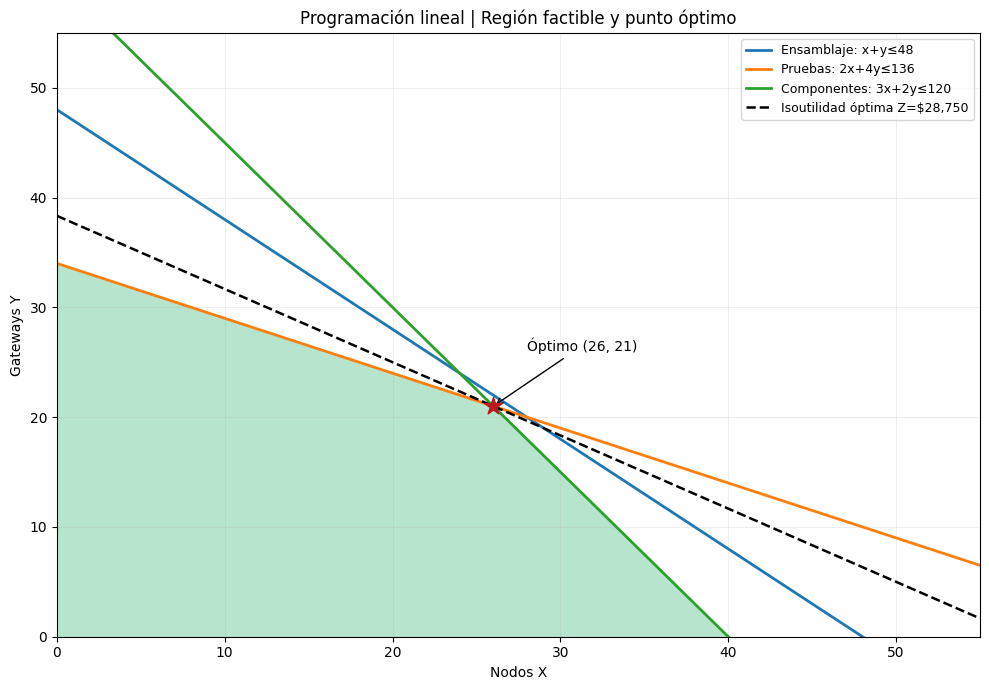

In [ ]:
fig,ax=plt.subplots(figsize=(10,7))
X,Y=np.meshgrid(np.linspace(0,55,500),np.linspace(0,55,500))
fact=(X>=0)&(Y>=0)
for j in range(3):fact &= (A[j,0]*X+A[j,1]*Y<=b[j]+1e-9)
ax.contourf(X,Y,fact.astype(int),levels=[.5,1.5],colors=['#a5dec0'],alpha=.8)
for j in range(3):ax.plot(xx,(b[j]-A[j,0]*xx)/A[j,1],lw=2,label=nombres[j])
ax.plot(xx,(zopt-utilidad[0]*xx)/utilidad[1],'k--',lw=1.8,label=f'Isoutilidad óptima Z=${zopt:,.0f}')
ax.scatter([xopt],[yopt],s=170,c='#b91c1c',marker='*',zorder=6)
ax.annotate(f'Óptimo ({xopt:.0f}, {yopt:.0f})',xy=(xopt,yopt),xytext=(xopt+2,yopt+5),arrowprops={'arrowstyle':'->'})
ax.set(xlim=(0,55),ylim=(0,55),xlabel='Nodos X',ylabel='Gateways Y',title='Programación lineal | Región factible y punto óptimo')
ax.legend(fontsize=9,loc='upper right');ax.grid(alpha=.2);plt.tight_layout();plt.show()

## 9. Revisión del uso de recursos y sensibilidad

Encontrar la combinación óptima es solo una parte del análisis. También necesitamos entender **qué recursos están limitando la producción** y cuáles todavía tienen capacidad disponible.

La **holgura** es la diferencia entre la cantidad disponible de un recurso y lo que realmente utilizamos. Si la holgura es cero, significa que ese recurso se está aprovechando por completo. Si es mayor que cero, todavía existe cierta capacidad sin utilizar.

También calculamos los **valores marginales o precios sombra**. En términos sencillos, indican cuánto podría aumentar la utilidad máxima si contáramos con una unidad adicional de un recurso, **siempre que el cambio sea suficientemente pequeño y no cambie la estructura de la solución óptima**. No deben interpretarse como una ganancia garantizada para cualquier aumento de capacidad.

Como SciPy resuelve una minimización de la utilidad negativa, ajustamos el signo de esos valores para interpretarlos como cambios en la utilidad positiva. Por último, el código hace una pequeña prueba: aumenta en **0.1 unidades** la capacidad de cada recurso, una por una, y compara el cambio real de la utilidad con el valor marginal calculado.

In [ ]:
usado=A@sol.x
marginales=-sol.ineqlin.marginals
reporte=recursos.copy()
reporte['Utilizado']=np.round(usado,3)
reporte['Holgura']=np.round(b-usado,3)
reporte['Valor marginal local (MXN/unidad)']=np.round(marginales,2)
display(reporte)
print('Comprobación de restricciones:', bool(np.all(usado<=b+1e-8)))
print('Solución entera:',bool(np.allclose(sol.x,np.round(sol.x))))
# Verificación de sensibilidad por incremento pequeño (una décima de unidad)
for i,n in enumerate(recursos['Recurso']):
 b2=b.copy();b2[i]+=.1
 prueba=linprog(-utilidad,A_ub=A,b_ub=b2,bounds=[(0,None)]*2,method='highs')
 print(f'{n}: variación de utilidad con +0.1 unidad: ${-prueba.fun-zopt:.4f} (predicción local ${.1*marginales[i]:.4f})')

,Recurso,Nodo X,Gateway Y,Disponible,Utilizado,Holgura,Valor marginal local (MXN/unidad)
0,Ensamblaje,1,1,48,47.0,1.0,0.00
1,Banco de pruebas,2,4,136,136.0,0.0,156.25
2,Componentes,3,2,120,120.0,0.0,62.50


Comprobación de restricciones: True
Solución entera: True
Ensamblaje: variación de utilidad con +0.1 unidad: $0.0000 (predicción local $0.0000)
Banco de pruebas: variación de utilidad con +0.1 unidad: $15.6250 (predicción local $15.6250)
Componentes: variación de utilidad con +0.1 unidad: $6.2500 (predicción local $6.2500)


## 10. Interpretación de resultados y conclusiones

Después de formular las restricciones, revisar los vértices y comprobar el resultado con SciPy, encontramos que la mejor decisión es fabricar **26 nodos sensores y 21 gateways cada semana**. Esta combinación permite obtener una **utilidad máxima de contribución de $28,750 MXN**, de acuerdo con los datos hipotéticos del ejercicio.

Podemos comprobar el resultado sustituyendo las cantidades en cada restricción:

- **Ensamblaje:** $26+21=47$ unidades utilizadas de un máximo de 48. **Sobra 1 unidad**.
- **Banco de pruebas:** $2(26)+4(21)=136$ unidades utilizadas de 136. **No sobra capacidad**.
- **Componentes:** $3(26)+2(21)=120$ unidades utilizadas de 120. **No sobran componentes**.
- **Utilidad:** $500(26)+750(21)=13\,000+15\,750=28\,750$ MXN.

Con estos cálculos observamos que el **banco de pruebas y los componentes son los recursos que limitan directamente la producción**. Aunque todavía queda una unidad de ensamblaje libre, disponer de más ensamblaje por sí solo no permite mejorar la utilidad mientras las otras dos capacidades sigan al máximo. Por eso su valor marginal local es cero. En cambio, ampliar un poco la disponibilidad de pruebas o componentes podría mejorar el resultado, según los valores marginales obtenidos.

Además, **la solución ya es entera**. Esto es importante porque estamos hablando de dispositivos físicos: no necesitamos redondear cantidades ni modificar la decisión propuesta.

**Conclusión individual (ejemplo para adaptar):** En esta práctica aprendí a convertir un problema de fabricación de equipos IoT en un modelo de programación lineal. Comprendí que no solo debemos considerar cuál producto deja mayor utilidad, sino también los materiales, el tiempo de pruebas y la capacidad de ensamblaje que necesita. Las gráficas y los cálculos me ayudaron a entender por qué la mejor solución es fabricar una combinación de ambos productos.

**Conclusión del equipo (propuesta para adaptar):** Mediante el modelo de programación lineal se determinó que producir 26 nodos sensores y 21 gateways proporciona la mayor utilidad semanal, equivalente a $28,750 MXN, sin superar los recursos disponibles. El resultado se comprobó tanto con el análisis de los vértices como con SciPy. Este procedimiento muestra cómo la optimización puede apoyar decisiones de producción y aprovechamiento de recursos en proyectos tecnológicos.

**Aspectos que habría que considerar en una situación real:** Antes de aplicar esta recomendación sería necesario comprobar la demanda de cada dispositivo, los costos reales, los tiempos de fabricación y la disponibilidad de materiales. Si hubiera pedidos mínimos, producción por lotes o una solución con cantidades decimales, sería necesario ajustar el modelo e incorporar, cuando corresponda, **programación entera** en lugar de redondear sin justificación.